# 1. Discretization

In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [139]:
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.metrics import accuracy_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

from sklearn.tree import DecisionTreeClassifier

In [140]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/tested.csv', usecols=['Age','Fare','Survived'])
df.dropna(inplace=True)

In [141]:
df.head()

,Survived,Age,Fare
0,0,34.5,7.8292
1,1,47.0,7.0000
2,0,62.0,9.6875
3,0,27.0,8.6625
4,1,22.0,12.2875


In [142]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [143]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=3)

In [144]:
clf = DecisionTreeClassifier()
clf.fit(X_train,y_train)

DecisionTreeClassifier()

In [145]:
y_pred = clf.predict(X_test)
accuracy_score(y_test,y_pred)

0.5522388059701493

In [146]:
clf = DecisionTreeClassifier()
print(np.mean(cross_val_score(clf,X,y,scoring='accuracy')))

0.5832654907281772


In [147]:
kbin_age = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile')
kbin_fare = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile')

In [148]:
trf = ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_fare,[1])
])

In [149]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [150]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)

DecisionTreeClassifier()

In [151]:
y_pred_trf = clf.predict(X_test_trf)
accuracy_score(y_test,y_pred_trf)

0.582089552238806

In [152]:
X_trf = trf.fit_transform(X)
clf  = DecisionTreeClassifier()
print(np.mean(cross_val_score(clf,X_trf,y, scoring = 'accuracy',cv=10)))

0.5590909090909092


In [153]:
def discretize(bins, strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal',strategy=strategy)
    kbin_fare= KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)

    trf = ColumnTransformer([
        ('first',kbin_age,[0]),
        ('second', kbin_fare,[1])
    ])

    X_trf = trf.fit_transform(X)
    clf = DecisionTreeClassifier()

    print(np.mean(cross_val_score(clf,X_trf,y,scoring='accuracy',cv=10)))

    plt.figure(figsize=(13,13))

    plt.subplot(2,2,1)
    plt.hist(X['Age'])
    plt.title('Before Age')

    plt.subplot(2,2,2)
    plt.hist(X_trf[:,0], color='red')
    plt.title('After Age')

    plt.subplot(2,2,3)
    plt.hist(X['Fare'])
    plt.title('Before Fare')

    plt.subplot(2,2,4)
    plt.hist(X_trf[:,1], color='red')
    plt.title('After Fare')

    plt.show()




0.5590909090909092


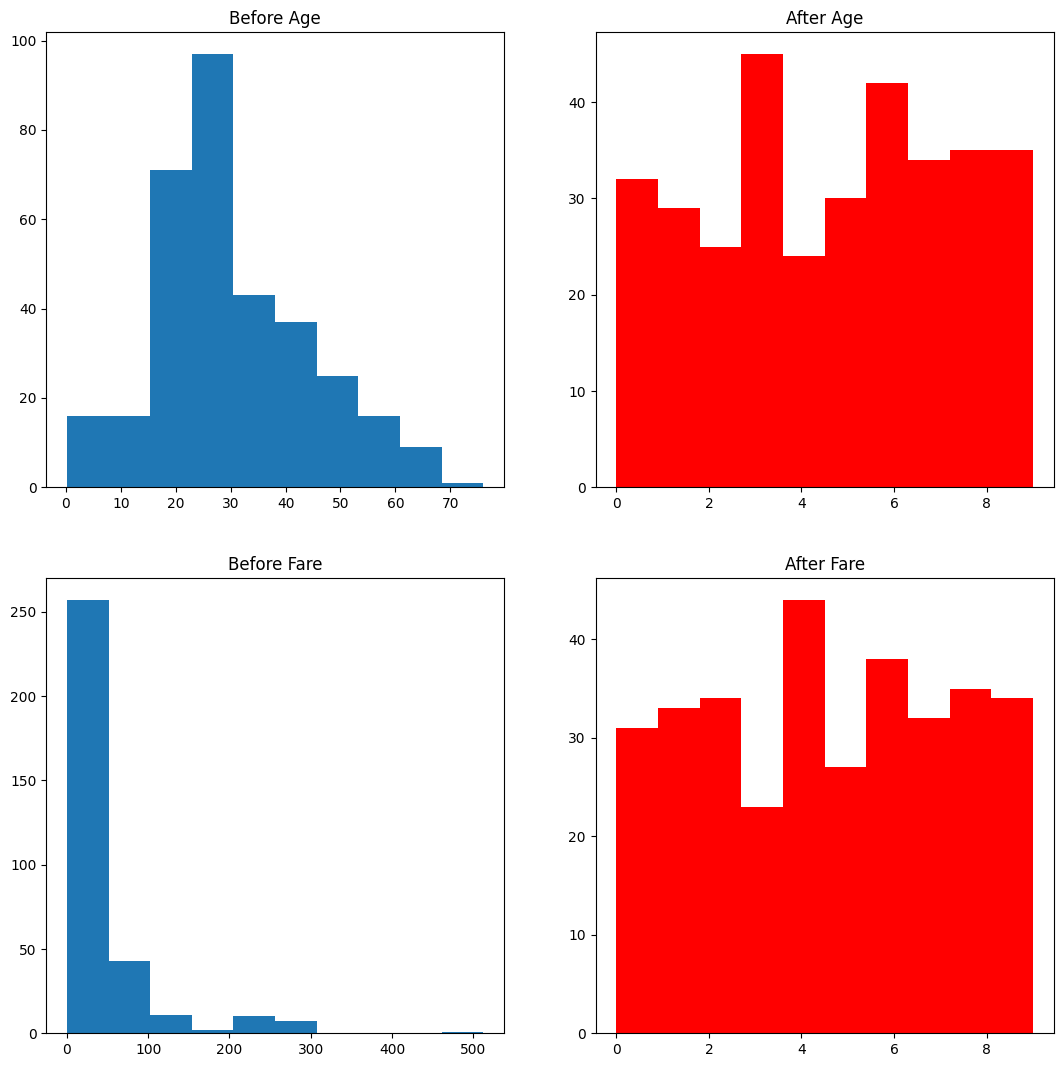

In [154]:
discretize(10,'quantile')

0.5923351158645277


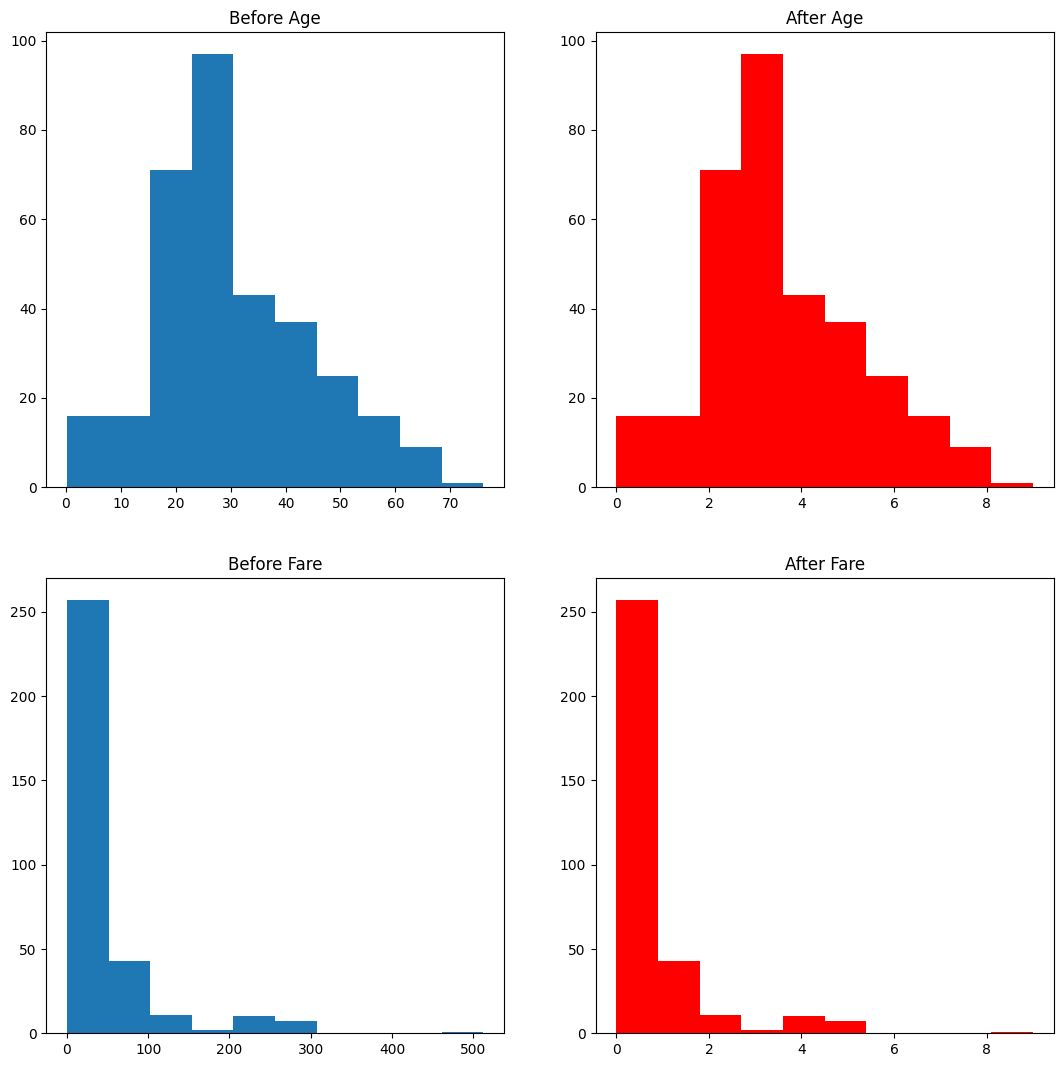

In [155]:
discretize(10,'uniform')

0.6223707664884136


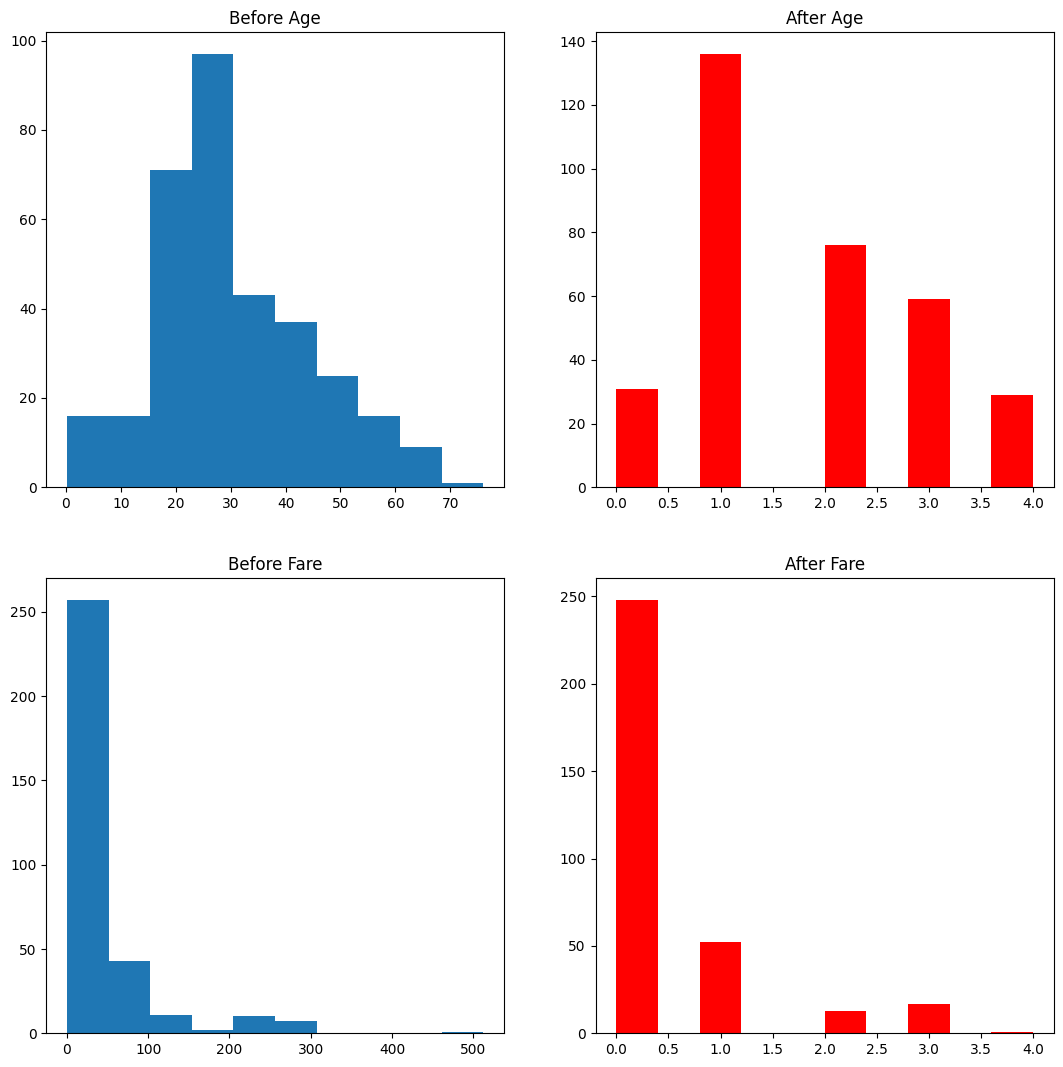

In [156]:
discretize(5,'kmeans')

# 2. Binarization

In [157]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/tested.csv', usecols=['Age','Fare','SibSp','Parch','Survived'])
df.dropna(inplace=True)
df['Family'] = df['SibSp']+df['Parch']
df.drop(columns=['SibSp','Parch'], inplace=True)
df.head()

,Survived,Age,Fare,Family
0,0,34.5,7.8292,0
1,1,47.0,7.0000,1
2,0,62.0,9.6875,0
3,0,27.0,8.6625,0
4,1,22.0,12.2875,2


In [158]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [159]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=42)

clf = DecisionTreeClassifier()
clf.fit(X_train,y_train)

y_pred = clf.predict(X_test)

accuracy_score(y_test, y_pred)

0.59

In [160]:
clf = DecisionTreeClassifier()

print(np.mean(cross_val_score(clf,X,y,scoring='accuracy',cv=10)))

0.6013368983957219


In [161]:
from sklearn.preprocessing import Binarizer
trf = ColumnTransformer([
    ('bin',Binarizer(copy=False),['Family'])
],remainder='passthrough')

In [162]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [165]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)

y_pred_trf = clf.predict(X_test_trf)

accuracy_score(y_test,y_pred_trf)

0.59